# Домашнє завдання 3 · Ознаки, аутлаєри та ICP
**Заняття 3 · OpenCV + Open3D · ≈ 2 години**

Дві частини, по одній на кожен спосіб оцінки руху з лекції. У дужках — назви слайдів, де пояснено теорію кроку.

| Частина | Що робимо | Слайди | Дані |
|---|---|---|---|
| **1 · 2D-2D** | ORB → зіставлення + ratio test → RANSAC і Essential matrix → поворот R і напрямок t | «Виявлення та зіставлення ознак» … «Як вирішують проблему масштабу на практиці?» | два кадри з набору Fountain + GT-пози камери (~33 МБ) |
| **2 · 3D-3D** | voxel downsampling → ICP з початковим наближенням і без нього → зшиті скани | «Підготовка хмари: вокселі й нормалі», «Метод 3D-to-3D», «ICP: як це працює», «ICP: поріг відповідностей і метрики» | два скани вітальні Redwood (~17 МБ) |

```
Частина 1:  кадр A, кадр B ──► ORB ──► knn + ratio test ──► RANSAC → E ──► recoverPose → R, t ──► порівняння з GT
Частина 2:  скан 1, скан 2 ──► voxel ──► ICP (старт від «IMU») ──► ICP без старту ──► зшита хмара .ply
```

**Як працювати.** Завантаження, візуалізацію та перевірки вже написано. Вам лишається вписати там, де стоїть `TODO`, **один виклик функції OpenCV/Open3D або значення параметра**. Формул писати не треба. Після кожного кроку є клітинка `check(...)`: ✅ означає, що крок виконано, ❌ — що треба ще покрутити (підказка завжди поруч).

**Що здати** — прикріпіть в особистому кабінеті LMS:
1. цей ноутбук **з виводами** (Kernel → Restart & Run All, потім зберегти), заповнені таблиці й відповіді в клітинках «✍️» (по 1–3 речення, своїми словами);
2. файл `outputs/room_merged.ply` (з'явиться поруч із ноутбуком після кроку 2.6).

**Середовище.** Ядро **Python (cv-advanced)**: усе потрібне, зокрема `open3d`, ставить `requirements.txt` з кореня репозиторію. Open3D працює на Python 3.10–3.12. Дані (~50 МБ) Open3D завантажить сам у `~/open3d_data` під час першого запуску.

| Крок | Бали |
|---|---|
| 1.2 · ORB | 1 |
| 1.3 · зіставлення, ratio test і таблиця збігів | 2 |
| 1.4 · RANSAC і Essential matrix | 2 |
| 1.5 · поворот і напрямок руху | 2 |
| 2.2 · voxel downsampling і вибір `VOXEL` | 2 |
| 2.3 · ICP від `T_INIT`, підбір `ICP_DIST` | 3 |
| 2.4 · ICP від `eye(4)` | 1 |
| 2.6 · здано `outputs/room_merged.ply` | 1 |
| 3 · питання | 4 × 1,5 |
| **Разом** | **20** |

Крок зараховано, якщо його `check()` дає ✅. Бонус не оцінюється.

In [1]:
from pathlib import Path
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
import open3d as o3d

o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
OUT_DIR = Path('outputs'); OUT_DIR.mkdir(exist_ok=True)

# Вікно Open3D зручніше (можна крутити мишею), але інколи не відкривається в Jupyter.
# False — картинки малює matplotlib прямо в ноутбуці (так їх побачить і викладач).
OPEN3D_WINDOW = False


def show_cloud(*clouds, title='', max_points=40_000, views=((20, -60), (75, -90))):
    # Показує одну чи кілька хмар точок. Колір — з хмари (якщо він є).
    if OPEN3D_WINDOW:
        o3d.visualization.draw_geometries(list(clouds), window_name=title)
        return
    pts = np.vstack([np.asarray(c.points) for c in clouds])
    cols = np.vstack([np.asarray(c.colors) if c.has_colors() else np.full((len(c.points), 3), 0.4) for c in clouds])
    if len(pts) > max_points:
        idx = np.random.default_rng(0).choice(len(pts), max_points, replace=False)
        pts, cols = pts[idx], cols[idx]
    x, y, z = pts[:, 0], pts[:, 2], -pts[:, 1]          # у камери вісь y дивиться вниз — перевертаємо
    fig = plt.figure(figsize=(6 * len(views), 4.8))
    for k, (elev, azim) in enumerate(views):
        ax = fig.add_subplot(1, len(views), k + 1, projection='3d')
        ax.scatter(x, y, z, c=np.clip(cols, 0, 1), s=1.0, linewidths=0)
        ax.view_init(elev, azim); ax.set_axis_off(); ax.set_box_aspect((np.ptp(x), np.ptp(y), np.ptp(z)), zoom=1.6)
    fig.suptitle(title); fig.subplots_adjust(0, 0, 1, 0.94, 0, 0); plt.show()


def show_images(*imgs, titles=(), size=6):
    fig, axes = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size * 0.75))
    for ax, im, t in zip(np.atleast_1d(axes), imgs, list(titles) + [''] * len(imgs)):
        ax.imshow(im, cmap='gray' if im.ndim == 2 else None); ax.set_title(t); ax.axis('off')
    plt.tight_layout(); plt.show()


def check(ok, good, bad):
    print(('✅ ' + good) if ok else ('❌ ' + bad))
    return ok


def paint(cloud, rgb):
    c = o3d.geometry.PointCloud(cloud); c.paint_uniform_color(rgb); return c


def rot_deg(R):
    # кут повороту матриці R, градуси
    return np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1)))


def angle_deg(a, b):
    # кут між двома векторами, градуси
    a, b = np.ravel(a), np.ravel(b)
    return np.degrees(np.arccos(np.clip(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)), -1, 1)))

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


# Частина 1 · Ознаки та оцінка руху 2D-2D

## 1.1 · Дані (≈ 5 хв)
Камера знімала фонтан, обходячи його. Беремо два кадри: між ними камера повернулась приблизно на 10° і зсунулась на 15 см. Для кожного кадру відома справжня поза (ground truth), тож ми зможемо перевірити, наскільки точно відновили рух.

Матриця камери `K` відома з калібрування (заняття 2). Тому працюємо з **Essential matrix** (слайд «Метод 2D-to-2D: монокулярна VO»), а не з Fundamental.

GT: поворот 10.2°, зсув 14.7 см


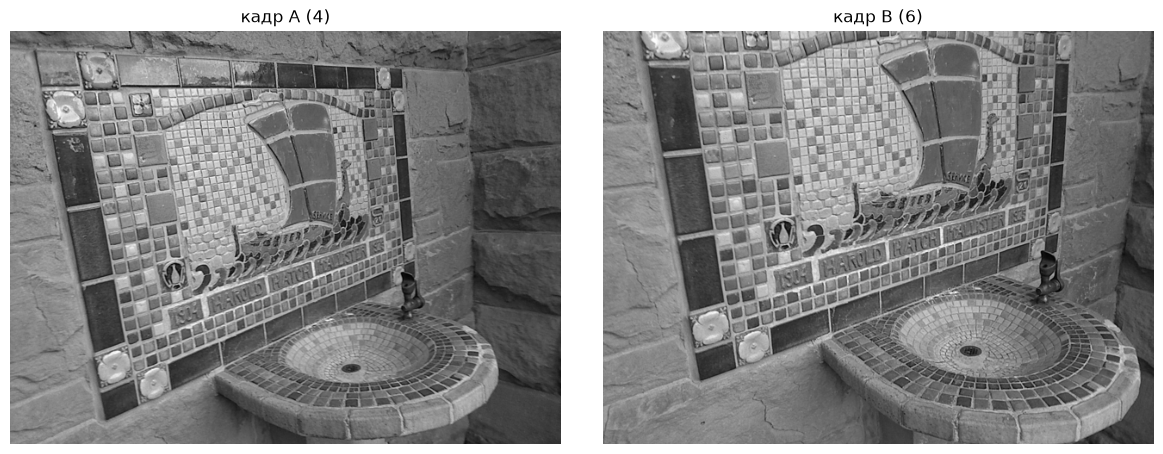

In [2]:
fountain = o3d.data.SampleFountainRGBDImages()
traj = o3d.io.read_pinhole_camera_trajectory(fountain.keyframe_poses_log_path)
K = np.array([[525.0, 0, 319.5], [0, 525.0, 239.5], [0, 0, 1]])   # калібрування камери PrimeSense

A, B = 4, 6                                                     # номери кадрів
img_a, img_b = [cv2.imread(fountain.color_paths[i], cv2.IMREAD_GRAYSCALE) for i in (A, B)]

# GT: X_b = R_gt · X_a + t_gt  (точка в системі камери A → у системі камери B)
T_gt = np.asarray(traj.parameters[B].extrinsic) @ np.linalg.inv(np.asarray(traj.parameters[A].extrinsic))
R_gt, t_gt = T_gt[:3, :3], T_gt[:3, 3]
print(f'GT: поворот {rot_deg(R_gt):.1f}°, зсув {np.linalg.norm(t_gt) * 100:.1f} см')
show_images(img_a, img_b, titles=(f'кадр A ({A})', f'кадр B ({B})'))

## 1.2 · Детекція ORB (≈ 10 хв)
ORB шукає кутоподібні точки (детектор FAST) і для кожної рахує **бінарний дескриптор**: 256 порівнянь яскравості пікселів довкола точки, тобто 32 байти (слайд «Візуальні дескриптори: математичне подання ознак»).

**TODO 1.2.** Створіть детектор ORB на 2000 точок і знайдіть точки та дескриптори на обох кадрах.

*Підказки:* `cv2.ORB_create(nfeatures=...)`; `orb.detectAndCompute(img, None)` повертає пару `(точки, дескриптори)`.

точок: A — 2000, B — 2000
дескриптори: форма (2000, 32), тип uint8 → 256 біт на точку


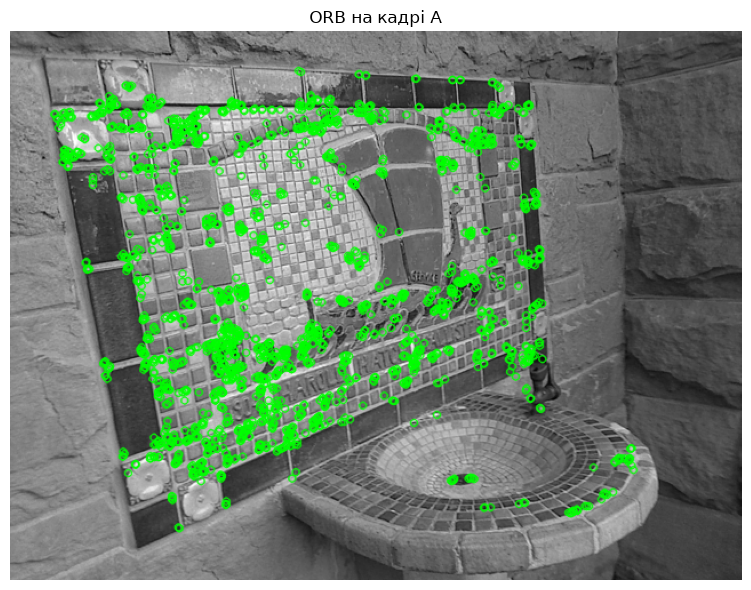

✅ ORB знайшов точки


True

In [3]:
orb = cv2.ORB_create(nfeatures=2000)               # TODO 1.2: детектор ORB на 2000 точок
kp_a, des_a = orb.detectAndCompute(img_a, None)       # TODO 1.2: точки й дескриптори кадру A
kp_b, des_b = orb.detectAndCompute(img_b, None)        # TODO 1.2: те саме для кадру B

print(f'точок: A — {len(kp_a)}, B — {len(kp_b)}')
print(f'дескриптори: форма {des_a.shape}, тип {des_a.dtype} → {des_a.shape[1] * 8} біт на точку')
show_images(cv2.drawKeypoints(img_a, kp_a, None, color=(0, 255, 0)), titles=('ORB на кадрі A',), size=8)
check(len(kp_a) >= 1000 and len(kp_b) >= 1000 and des_a.dtype == np.uint8,
      'ORB знайшов точки', 'точок замало або дескриптори не ORB — перевірте nfeatures і виклик detectAndCompute')

Для порівняння — SIFT на тому самому кадрі (той самий слайд: «128-мірний вектор float»). Подивіться на час і розмір дескриптора.

In [4]:
for name, det in [('ORB', cv2.ORB_create(2000)), ('SIFT', cv2.SIFT_create(2000))]:
    t0 = time.perf_counter(); _, d = det.detectAndCompute(img_a, None); ms = (time.perf_counter() - t0) * 1000
    print(f'{name:>4}: {ms:6.1f} мс, дескриптор {d.shape[1]} × {d.dtype} = {d.shape[1] * d.itemsize} байт')

 ORB:    7.7 мс, дескриптор 32 × uint8 = 32 байт
SIFT:   22.5 мс, дескриптор 128 × float32 = 512 байт


✍️ **Зверніть увагу:** де на кадрі скупчились точки ORB, а де їх майже немає? (Не оцінюється — знадобиться для питань.)

## 1.3 · Зіставлення і ratio test Лоу (≈ 15 хв)
Для кожного дескриптора кадру A шукаємо **двох** найближчих сусідів у кадрі B за **відстанню Хеммінга** — кількістю різних бітів (слайд «Зіставлення ознак та робастне оцінювання»). Далі ratio test: збіг приймаємо, лише якщо найкращий сусід помітно ближчий за другого, `d₁ < ratio · d₂`. Так відсіюються неоднозначні збіги на повторюваних текстурах — а мозаїка фонтану саме така: сотні однакових плиток.

**TODO 1.3.** (а) Створіть matcher із метрикою Хеммінга і знайдіть 2 найближчих сусіди. (б) Допишіть умову ratio test.

*Підказки:* `cv2.BFMatcher(cv2.NORM_HAMMING)`; `matcher.knnMatch(des_a, des_b, k=2)`. Кожен елемент `knn` — пара `(m, n)`, де `m.distance` і `n.distance` — відстані до 1-го і 2-го сусіда.

ratio = 0.6  →   326 збігів
ratio = 0.75 →   629 збігів
ratio = 0.9  →  1041 збігів
ratio = 1.0  →  1879 збігів


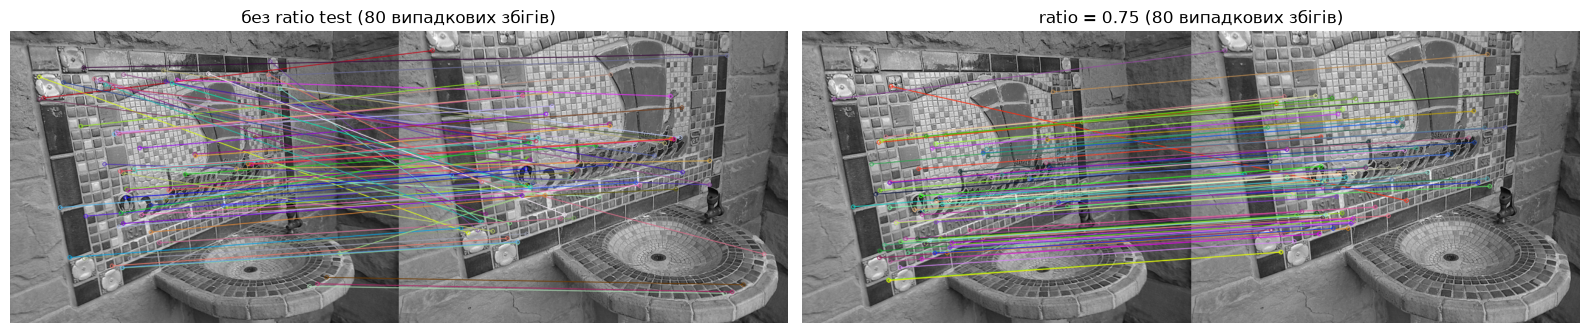

✅ 629 збігів після ratio test


True

In [5]:
matcher = cv2.BFMatcher(cv2.NORM_HAMMING)            # TODO 1.3а: matcher з відстанню Хеммінга
knn = matcher.knnMatch(des_a, des_b, 2)                # TODO 1.3а: 2 найближчих сусіди для кожної точки A


def ratio_test(knn, ratio):
    pairs = [p for p in knn if len(p) == 2]
    return [m for m, n in pairs if m.distance < ratio * n.distance]   # TODO 1.3б: умова Лоу


for r in [0.6, 0.75, 0.9, 1.0]:
    print(f'ratio = {r:<4} → {len(ratio_test(knn, r)):>5} збігів')
RATIO = 0.75
good = ratio_test(knn, RATIO)
rng = np.random.default_rng(0)
sample = lambda ms: list(rng.choice(ms, min(80, len(ms)), replace=False))
flags = cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
show_images(cv2.drawMatches(img_a, kp_a, img_b, kp_b, sample(ratio_test(knn, 1.0)), None, flags=flags),
            cv2.drawMatches(img_a, kp_a, img_b, kp_b, sample(good), None, flags=flags),
            titles=('без ratio test (80 випадкових збігів)', f'ratio = {RATIO} (80 випадкових збігів)'), size=8)
check(300 <= len(good) < len(ratio_test(knn, 1.0)), f'{len(good)} збігів після ratio test',
      f'{len(good)} збігів — перевірте умову: найкращий сусід має бути ближчим за ratio × другий')

✍️ **Заповніть таблицю** (числа з виводу):

| ratio | збігів |
|---|---|
| 0.6 | 326 |
| 0.75 | 629 |
| 0.9 | 1041 |
| 1.0 (без тесту) | 1879 |

## 1.4 · RANSAC і Essential matrix (≈ 15 хв)
Навіть після ratio test частина збігів хибна. `findEssentialMat` запускає RANSAC (слайд «RANSAC проти найменших квадратів»): багато разів бере 5 випадкових пар, рахує E алгоритмом Ністера і перевіряє, скільки інших пар задовольняють епіполярне обмеження з точністю до порогу в пікселях. Перемагає E з найбільшою кількістю інлаєрів, а `mask` позначає, які пари вони.

**TODO 1.4.** Оцініть E з RANSAC: ймовірність `0.999`, поріг `1.0` пікселя.

*Підказка:* `cv2.findEssentialMat(pts_a, pts_b, K, cv2.RANSAC, 0.999, 1.0)` повертає `(E, mask)`.

інлаєрів 469 з 629 (75%), аутлаєрів 160


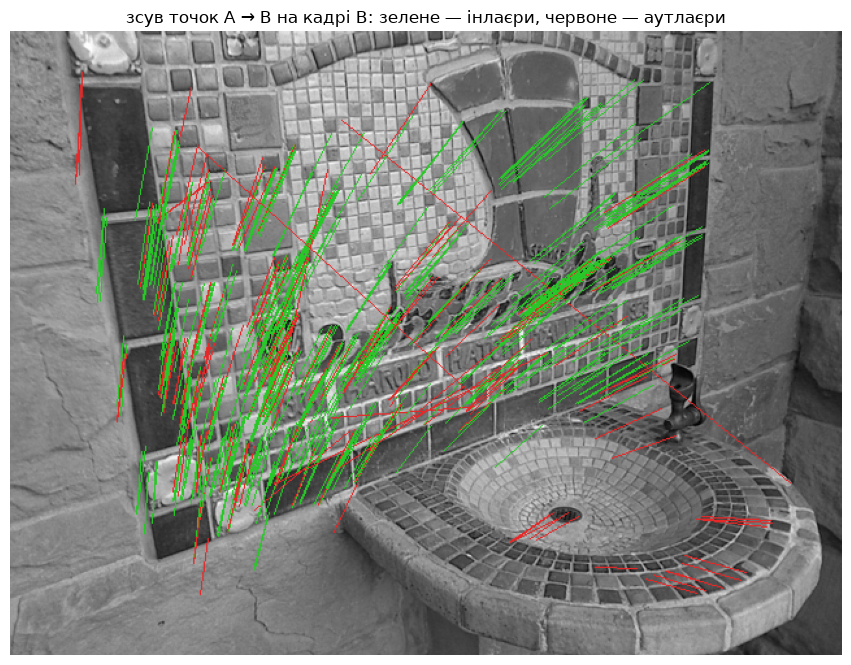

✅ E знайдено, інлаєрів 75%


np.True_

In [6]:
pts_a = np.float32([kp_a[m.queryIdx].pt for m in good])
pts_b = np.float32([kp_b[m.trainIdx].pt for m in good])

E, mask = cv2.findEssentialMat(pts_a, pts_b, K, cv2.RANSAC, 0.999, 1.0)   # TODO 1.4: E з RANSAC
inl = mask.ravel().astype(bool)
print(f'інлаєрів {inl.sum()} з {len(inl)} ({inl.mean():.0%}), аутлаєрів {(~inl).sum()}')

vis = cv2.cvtColor(img_b, cv2.COLOR_GRAY2RGB)
for (xa, ya), (xb, yb), ok in zip(pts_a, pts_b, inl):
    cv2.line(vis, (int(xa), int(ya)), (int(xb), int(yb)), (40, 200, 40) if ok else (230, 40, 40), 1)
show_images(vis, titles=('зсув точок A → B на кадрі B: зелене — інлаєри, червоне — аутлаєри',), size=9)
check(E is not None and E.shape == (3, 3) and inl.mean() >= 0.5, f'E знайдено, інлаєрів {inl.mean():.0%}',
      'E не знайдено або інлаєрів менше 50 % — перевірте аргументи findEssentialMat')

## 1.5 · Поворот і напрямок руху (≈ 10 хв)
E розкладається через SVD на 4 варіанти `[R|t]`, і лише в одному точки лежать **перед** обома камерами (cheirality check, слайд «Метод 2D-to-2D: алгоритм обчислення зміщення»). Усе це робить `recoverPose`.

**TODO 1.5.** Відновіть R і t з E (тільки на інлаєрах, тому передайте `mask`).

*Підказка:* `cv2.recoverPose(E, pts_a, pts_b, K, mask=mask)` повертає `(кількість_точок, R, t, mask)`.

In [7]:
_, R, t, _ = cv2.recoverPose(E, pts_a, pts_b, K, mask=mask)   # TODO 1.5: R і t з E

rot_err, dir_err = rot_deg(R.T @ R_gt), angle_deg(t, t_gt)
print(f'поворот:  оцінка {rot_deg(R):5.2f}°,  GT {rot_deg(R_gt):5.2f}°,  похибка {rot_err:.2f}°')
print(f'напрямок зсуву: похибка {dir_err:.1f}°')
print(f'довжина зсуву: оцінка {np.linalg.norm(t):.2f} (?),  GT {np.linalg.norm(t_gt):.3f} м')
check(rot_err <= 3 and dir_err <= 20, 'рух відновлено', f'похибка повороту {rot_err:.1f}° (треба ≤ 3°), '
      f'напрямку {dir_err:.0f}° (треба ≤ 20°) — перевірте кроки 1.3–1.4')

поворот:  оцінка  5.51°,  GT 10.24°,  похибка 6.69°
напрямок зсуву: похибка 57.8°
довжина зсуву: оцінка 1.00 (?),  GT 0.147 м
❌ похибка повороту 6.7° (треба ≤ 3°), напрямку 58° (треба ≤ 20°) — перевірте кроки 1.3–1.4


np.False_

## 1.6 · Експеримент: що робить RANSAC (≈ 5 хв, код готовий)
Повторимо оцінку для різних порогів ratio test і порівняємо два способи:
- **RANSAC + 5 точок** — як у кроці 1.4;
- **8 точок на всіх збігах без RANSAC** — Fundamental matrix за всіма парами, потім `E = Kᵀ F K`. Кожен збіг, зокрема хибний, «голосує» з однаковою вагою.

Просто запустіть клітинку і подивіться на таблицю. Вона знадобиться для питання 3.1.

In [8]:
print(f"{'ratio':>6} {'збігів':>7} {'інлаєрів':>9} │ {'похибка R, RANSAC':>18} │ {'похибка R, 8 точок без RANSAC':>30}")
for r in [0.6, 0.75, 0.9, 1.0]:
    g = ratio_test(knn, r)
    pa = np.float32([kp_a[m.queryIdx].pt for m in g]); pb = np.float32([kp_b[m.trainIdx].pt for m in g])
    E_r, m_r = cv2.findEssentialMat(pa, pb, K, cv2.RANSAC, 0.999, 1.0)
    _, R_r, _, _ = cv2.recoverPose(E_r, pa, pb, K, mask=m_r.copy())
    F, _ = cv2.findFundamentalMat(pa, pb, cv2.FM_8POINT)
    _, R_8, _, _ = cv2.recoverPose(K.T @ F @ K, pa, pb, K)
    print(f'{r:>6} {len(g):>7} {m_r.mean():>9.0%} │ {rot_deg(R_r.T @ R_gt):>17.1f}° │ {rot_deg(R_8.T @ R_gt):>29.1f}°')

 ratio  збігів  інлаєрів │  похибка R, RANSAC │  похибка R, 8 точок без RANSAC
   0.6     326       83% │               1.7° │                           2.4°
  0.75     629       75% │               6.7° │                           2.5°
   0.9    1041       65% │               1.4° │                          46.3°
   1.0    1879       46% │               0.8° │                          84.0°


# Частина 2 · Хмари точок і ICP (3D-3D)

## 2.1 · Дані (≈ 5 хв)
Два скани однієї вітальні з RGB-D камери, зняті з різних місць. Кожен записаний у системі координат камери в момент знімання, тому без вирівнювання вони лежать один на одному як попало. Задача ICP (слайди «Метод 3D-to-3D: стерео / RGB-D VO» і «ICP: як це працює») — знайти поворот і зсув, які кладуть скан `source` на скан `target`.

source: 198,835 точок, габарити 3.4 × 1.6 × 2.0 м
target: 137,833 точок, габарити 2.3 × 1.6 × 1.2 м


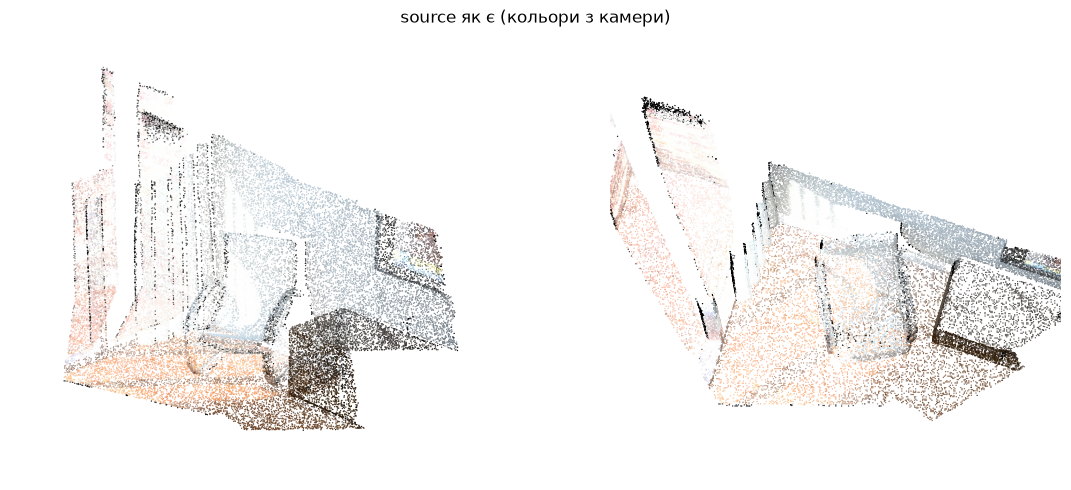

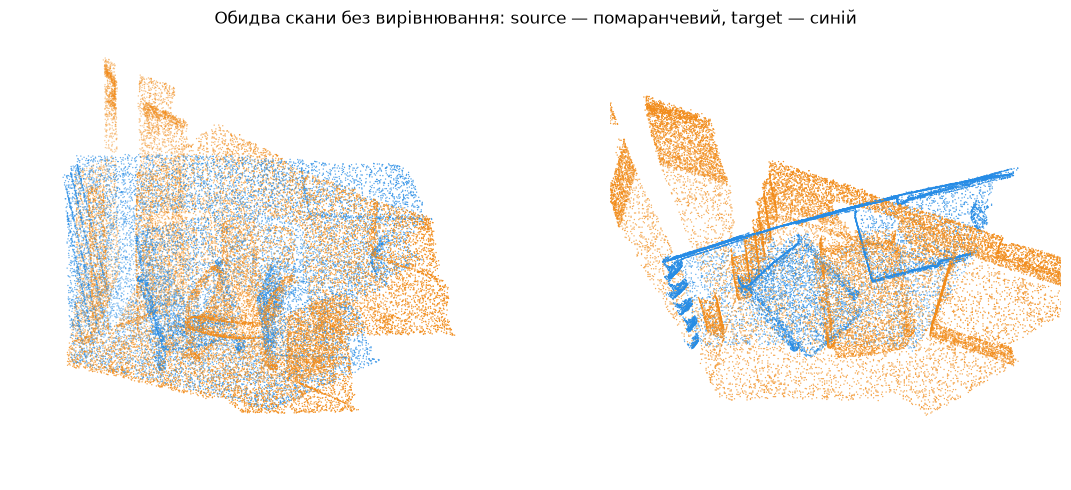

In [9]:
paths = o3d.data.DemoICPPointClouds().paths
source, target = o3d.io.read_point_cloud(paths[0]), o3d.io.read_point_cloud(paths[1])
for name, c in [('source', source), ('target', target)]:
    size = c.get_axis_aligned_bounding_box().get_extent()
    print(f'{name}: {len(c.points):>7,} точок, габарити {size[0]:.1f} × {size[1]:.1f} × {size[2]:.1f} м')

ORANGE, BLUE = [0.95, 0.55, 0.1], [0.15, 0.55, 0.9]
show_cloud(source, title='source як є (кольори з камери)')
show_cloud(paint(source, ORANGE), paint(target, BLUE), title='Обидва скани без вирівнювання: source — помаранчевий, target — синій')

## 2.2 · Проріджування вокселями (≈ 10 хв)
200 тисяч точок — забагато для швидкого ICP, а сусідні точки часто стоять за кілька міліметрів одна від одної. **Voxel downsampling** ділить простір на кубики (вокселі) зі стороною `voxel_size` і з усіх точок в одному кубику лишає одну (слайд «Підготовка хмари: вокселі й нормалі»).

**TODO 2.2.** Допишіть виклик проріджування, подивіться на кількість точок для різних розмірів і виберіть `VOXEL`, за якого кімната ще впізнавана, а точок у `source` 15–60 тисяч.

*Підказка:* `cloud.voxel_down_sample(voxel_size=...)`

voxel 0.01 м →  95,354 точок


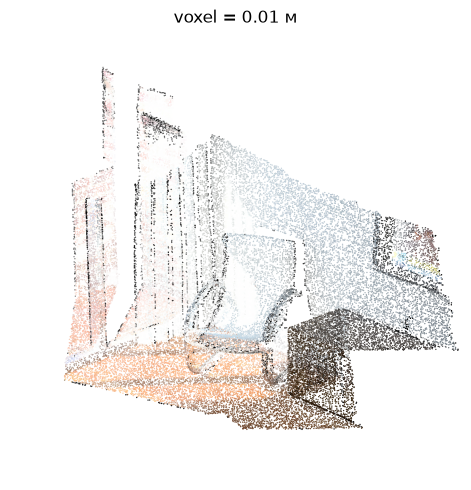

voxel 0.02 м →  27,211 точок


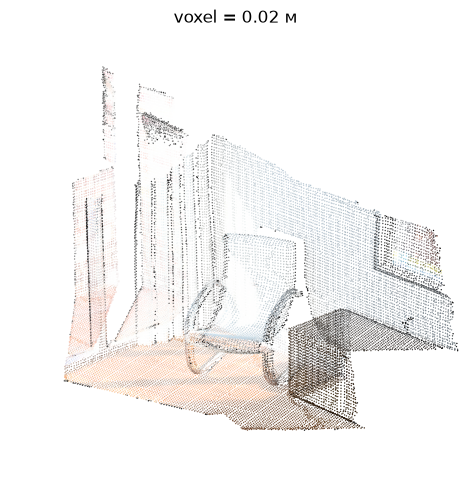

voxel 0.05 м →   4,760 точок


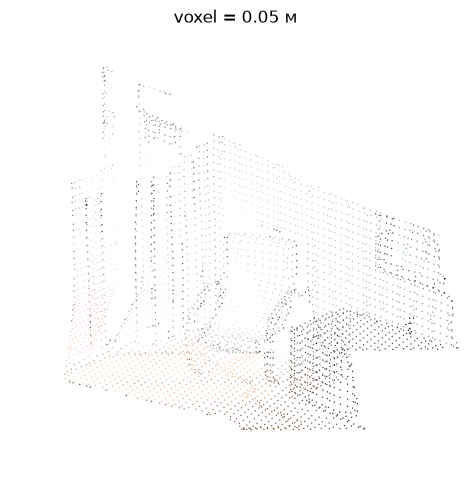

voxel  0.1 м →   1,301 точок


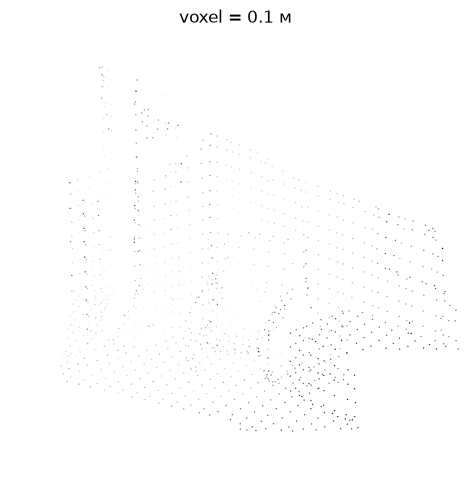

In [10]:
for v in [0.01, 0.02, 0.05, 0.1]:
    small = source.voxel_down_sample(voxel_size=v)   # TODO 2.2: проріджена копія source з розміром вокселя v
    print(f'voxel {v:>4} м → {len(small.points):>7,} точок')
    show_cloud(small, title=f'voxel = {v} м', views=((20, -60),))

In [11]:
VOXEL = 0.02   # TODO 2.2: ваш вибір, м
src, tgt = source.voxel_down_sample(VOXEL), target.voxel_down_sample(VOXEL)
for c in (src, tgt):                             # нормалі потрібні варіанту ICP «точка-площина»
    c.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=2 * VOXEL, max_nn=30))
check(15_000 <= len(src.points) <= 60_000, f'VOXEL = {VOXEL} м, {len(src.points):,} точок',
      f'{len(src.points):,} точок — оберіть VOXEL так, щоб лишилось 15–60 тис.')

✅ VOXEL = 0.02 м, 27,211 точок


True

## 2.3 · ICP з початковим наближенням (≈ 15 хв)
ICP на кожній ітерації зіставляє кожну точку `source` з найближчою точкою `target` (якщо вона ближче за `ICP_DIST`), рахує поворот і зсув, що зводять пари докупи, і повторює. Він точний, **але тільки якщо стартувати вже майже з правильного положення**.

У реальній системі грубе наближення дає інший сенсор: IMU, колісна одометрія або модель сталої швидкості (слайд «Методи мінімізації помилки накопичення (дрифту)», блок Sensor Fusion). Тут його вже дано як `T_INIT`.

Як читати результат:
- `fitness` — частка точок `source`, які знайшли пару ближче за поріг (1.0 = усі);
- `inlier_rmse` — середня відстань між такими парами, м (менше — краще).

`fitness` залежить від порогу: з порогом 30 см «пару» знайде майже кожна точка. Тому якість **завжди міряємо з одним порогом 2 см**, хоч би яким був `ICP_DIST`.

**TODO 2.3.** Запустіть ICP від `T_INIT` і підберіть `ICP_DIST` так, щоб **fitness ≥ 0.55 і rmse ≤ 10 мм** (при порозі 2 см).

*Підказка:* `REG.registration_icp(src, tgt, ICP_DIST, T_INIT, REG.TransformationEstimationPointToPlane())` повертає результат з полями `.transformation`, `.fitness`, `.inlier_rmse`. Пробуйте `ICP_DIST` від 0.01 до 0.3.

In [12]:
REG = o3d.pipelines.registration
T_INIT = np.array([[0.862, 0.011, -0.507, 0.5],     # грубе наближення «від IMU»
                   [-0.139, 0.967, -0.215, 0.7],
                   [0.487, 0.255, 0.835, -1.4],
                   [0.0, 0.0, 0.0, 1.0]])
res = REG.registration_icp(src, tgt, 0.1, T_INIT, REG.TransformationEstimationPointToPlane())
res.transformation

array([[ 0.84068558,  0.0058142 , -0.54174325,  0.64925789],
       [-0.14755861,  0.96498186, -0.21836397,  0.81183019],
       [ 0.52058449,  0.26269984,  0.81199164, -1.48163528],
       [ 0.        ,  0.        ,  0.        ,  1.        ]])

In [13]:
res.fitness

0.681856602109441

In [14]:
res.inlier_rmse

0.018948345474541915

старт T_INIT: fitness = 0.16, rmse = 12.9 мм
після ICP:    fitness = 0.63, rmse = 9.7 мм
ICP виправив старт на 2.4° і 20 см


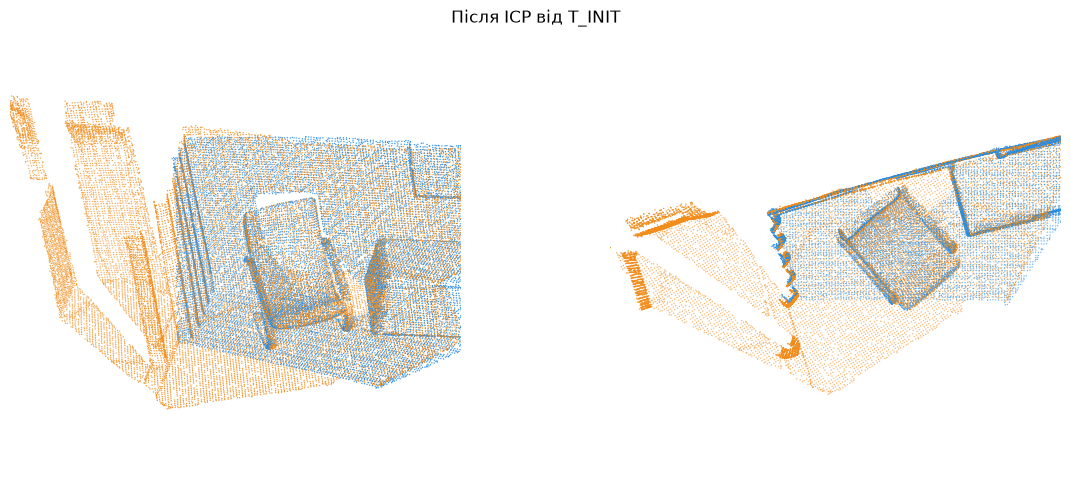

✅ скани зшито


True

In [15]:
REG = o3d.pipelines.registration
T_INIT = np.array([[0.862, 0.011, -0.507, 0.5],     # грубе наближення «від IMU»
                   [-0.139, 0.967, -0.215, 0.7],
                   [0.487, 0.255, 0.835, -1.4],
                   [0.0, 0.0, 0.0, 1.0]])


def placed(cloud, T):
    c = o3d.geometry.PointCloud(cloud); c.transform(T); return c


def quality(T):
    return REG.evaluate_registration(src, tgt, 0.02, T)       # якість при фіксованому порозі 2 см


ICP_DIST = 0.1   # TODO 2.3: м
fine =  REG.registration_icp(src, tgt, 0.1, T_INIT, REG.TransformationEstimationPointToPlane()) # TODO 2.3: ICP від T_INIT

q0, q = quality(T_INIT), quality(fine.transformation)
dT = np.linalg.inv(T_INIT) @ fine.transformation
print(f'старт T_INIT: fitness = {q0.fitness:.2f}, rmse = {q0.inlier_rmse * 1000:.1f} мм')
print(f'після ICP:    fitness = {q.fitness:.2f}, rmse = {q.inlier_rmse * 1000:.1f} мм')
print(f'ICP виправив старт на {rot_deg(dT[:3, :3]):.1f}° і {np.linalg.norm(dT[:3, 3]) * 100:.0f} см')
show_cloud(paint(placed(src, fine.transformation), ORANGE), paint(tgt, BLUE), title='Після ICP від T_INIT')
check(q.fitness >= 0.55 and q.inlier_rmse <= 0.010, 'скани зшито',
      f'fitness {q.fitness:.2f} (треба ≥ 0.55), rmse {q.inlier_rmse * 1000:.1f} мм (треба ≤ 10) — змініть ICP_DIST')

## 2.4 · А якщо старту немає? (≈ 5 хв)
**TODO 2.4.** Запустіть той самий ICP з тим самим `ICP_DIST`, але від одиничної матриці `np.eye(4)` («скани вже на місці»). Порівняйте fitness і картинку з кроком 2.3.

In [16]:
REG = o3d.pipelines.registration
res2 = REG.registration_icp(src, tgt, 0.05, np.eye(4), REG.TransformationEstimationPointToPlane())
res2.transformation

array([[ 0.99808737,  0.00953131, -0.06107993,  0.15880844],
       [-0.02431093,  0.96895076, -0.24605568,  0.5436292 ],
       [ 0.05683821,  0.24706998,  0.96732923, -0.53754873],
       [ 0.        ,  0.        ,  0.        ,  1.        ]])

ICP від eye(4): fitness = 0.14, rmse = 11.6 мм   (від T_INIT було 0.63)


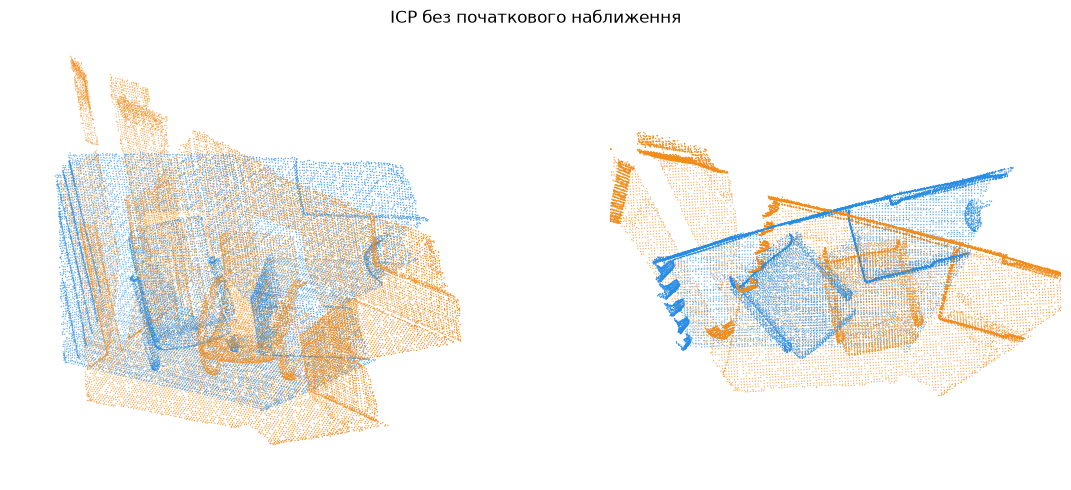

✅ ICP без старту помітно гірший — так і має бути


True

In [17]:
bad = res2   # TODO 2.4: ICP від np.eye(4)

q_bad = quality(bad.transformation)
print(f'ICP від eye(4): fitness = {q_bad.fitness:.2f}, rmse = {q_bad.inlier_rmse * 1000:.1f} мм   (від T_INIT було {q.fitness:.2f})')
show_cloud(paint(placed(src, bad.transformation), ORANGE), paint(tgt, BLUE), title='ICP без початкового наближення')
check(bad is not None and q_bad.fitness < q.fitness, 'ICP без старту помітно гірший — так і має бути',
      'ICP від eye(4) не гірший за ICP від T_INIT — перевірте, що стартуєте саме з np.eye(4)')

## 2.5 · Експеримент: поріг ICP_DIST (≈ 5 хв, код готовий)
Та сама пара сканів, різні пороги, два старти. У клітинках — fitness при порозі 2 см (≥ 0.55 означає, що зшито). Запустіть і подивіться. Таблиця знадобиться для питання 3.3.

In [18]:
print(f"{'ICP_DIST, м':>12} │ {'від T_INIT':>10} │ {'від eye(4)':>10}")
for d in [0.01, 0.02, 0.05, 0.1, 0.3]:
    row = [quality(REG.registration_icp(src, tgt, d, T0, REG.TransformationEstimationPointToPlane()).transformation).fitness
           for T0 in (T_INIT, np.eye(4))]
    print(f'{d:>12} │ {row[0]:>10.2f} │ {row[1]:>10.2f}')

 ICP_DIST, м │ від T_INIT │ від eye(4)
        0.01 │       0.17 │       0.04
        0.02 │       0.34 │       0.05
        0.05 │       0.62 │       0.14
         0.1 │       0.63 │       0.14
         0.3 │       0.48 │       0.48


## 2.6 · Зшита хмара (≈ 2 хв, код готовий)

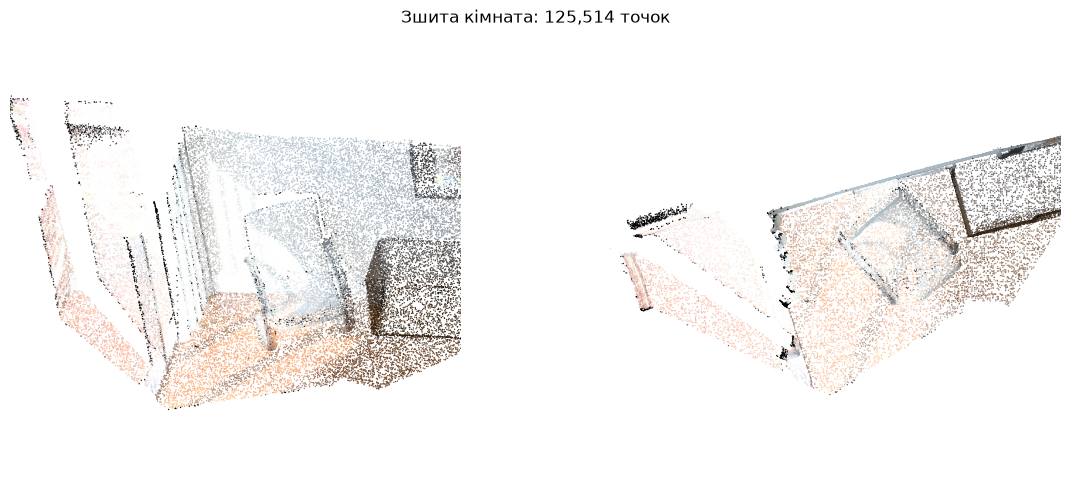

✅ outputs/room_merged.ply збережено


True

In [19]:
merged = (placed(source, fine.transformation) + target).voxel_down_sample(VOXEL / 2)
o3d.io.write_point_cloud(str(OUT_DIR / 'room_merged.ply'), merged)
show_cloud(merged, title=f'Зшита кімната: {len(merged.points):,} точок')
check((OUT_DIR / 'room_merged.ply').exists(), 'outputs/room_merged.ply збережено', 'файл не збережено')

Щоб покрутити результат, відкрийте `outputs/room_merged.ply` у будь-якому 3D-переглядачі (MeshLab, Blender, «3D Viewer» у Windows) або виконайте `o3d.visualization.draw_geometries([merged])`.

# 3 · Питання (≈ 10 хв)
Відповідайте своїми словами, по 1–3 речення. Формули не потрібні.

**3.1.** За таблицею з кроку 1.6: як змінюються кількість збігів і частка інлаєрів зі зростанням порогу ratio? Чому з RANSAC поворот майже не псується, а метод 8 точок без RANSAC при 0.9–1.0 «ламається»? (слайд «RANSAC проти найменших квадратів»)

✍️ *Ваша відповідь:*
Коли ми збільшуєм поріг, то і кількість аутлаєрів збільшується що впливає на зменшення тоді і частки інлаєрів. Задача RANSAC це відсіювання otliers, щоб зменшити похибку яка впливає на вибір точок, якби ми просто використовували б MSE то похибка піднеслась би до квадрату і це вплинуло б на результат, тут же використовується knn для знаходження інлаєрів. Без RANSAC використовуються також помилкові збіги.

**3.2.** `recoverPose` повернув зсув довжиною 1, а справжній — близько 15 см. Чому монокулярна оцінка не може дати метри? Чим цей масштаб отримали б на дроні? (слайди «Проблема масштабу в монокулярній VO» і «Як вирішують проблему масштабу на практиці?»)

✍️ *Ваша відповідь:*
На дроні цей масштаб можна отримати додатково з інших сенсорів (IMU) або sensor fusion, або за допомогою відомого обєкта, датчики висоти до відомого обєкта чи за допомогою нейромережі. На зображенні за певного розсташування об'єктів різних розмірів вони можуть займати однакову кількість пікселів. за двома зображеннями з одної камери неможливо визначить масштаб руху.


**3.3.** Чому ICP від `eye(4)` не зшив скани, а від `T_INIT` зшив? Чому завеликий `ICP_DIST` (0.3 м) теж погіршує результат, навіть зі стартом `T_INIT`? (таблиця 2.5, слайди «ICP: як це працює» і «ICP: поріг відповідностей і метрики»)

✍️ *Ваша відповідь:*
eye(4) це рандомна ініціалізація звідки рухатись для зшивання сканів, з використання T_INIT це наближені значення від сенсора, тому результати кращі. Щодо ICP_DIST то це відстань між точками які ми шукаєм, надто велика відстань то точки можуть бути з різних поверхонь.

**3.4.** Уявіть, що сканів не 2, а 50: ви обійшли весь будинок і зшиваєте кожен скан з попереднім (1→0, 2→1, 3→2, …). Кожне зшивання має маленьку похибку. Що станеться з моделлю, коли ви повернетеся до першої кімнати? Як цю проблему вирішує SLAM? (слайди «Дрейф: чому одометрії ніколи не достатньо», «Loop closure (замикання петлі)» і «Інтеграція обмежень замикання циклу»)

✍️ *Ваша відповідь:*
З VO ми накопичуєм дрейф, SLAM зберігає просторові звязки між різними моментами завдяки loop closure. VO уникнути похибки неможливо без знання масштабу, тому з кожною наступною ітераціє зшивання сканів, похибка буде рости.

## Бонус (за бажанням)
- **Великий поворот.** Повторіть частину 1 для кадрів `A, B = 2, 4` (поворот ≈ 30°). Скільки збігів лишилось і як змінилась похибка?
- **SIFT замість ORB.** У кроці 1.2 використайте `cv2.SIFT_create(2000)`, а в 1.3 — `cv2.BFMatcher(cv2.NORM_L2)`. Чи стала оцінка точнішою? Чого це коштувало за часом?
- **Лідар з авто.** Завантажте KITTI (`python tools/fetch_kitti.py`) і запустіть `kiss_icp_pipeline --dataloader kitti --sequence 00 --n-scans 300 artifacts/kitti` (на Windows консольна команда падає на символьному посиланні — викличте KISS-ICP з Python, як у demo3 заняття). Порівняйте траєкторію з GT: `python lessons/03-odometry-slam/lesson03_demo1_kitti_rerun.py --frames 300 --est-poses <результат>.txt`.